In [ ]:
import os
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import sys
import anndata as ad
import numpy as np
import scipy.io


In [ ]:
def gene_lambda_by_ct(adata, ctcol = 'group'):
    pdlst=[]
    #celltypes_group = celltypes.groupby(ctcol).count().index.tolist()
    celltypes_group = list(set(adata.obs[ctcol].values))
    for ct in celltypes_group:
        ctbars = adata[adata.obs[ctcol] == ct].obs.index.tolist()
        print(f'[Log] {len(ctbars)} cells for cell type {ct}')
        cellbygenecount = adata.layers['counts'][adata.obs.index.isin(ctbars), :]
        print(f'dimension of cell by gene count', cellbygenecount.shape)
        cellbygene = pd.DataFrame(cellbygenecount.todense(), index = ctbars, columns = adata.var_names)
        genebycell = cellbygene.T
        # gene normalize expr per cell (gene count ratio over all gene count), then mean over all cells from that type.
        genenorm = (genebycell/(genebycell.sum(axis=0)))
        genenorm = genenorm.mean(axis=1) # normalized gene expr for this cell type.
        pdlst.append( 
            pd.DataFrame(genenorm, columns = [ct], index = adata.var_names)
        )

    genemeanpd = pd.concat(pdlst,axis=1)
    genemeanpdfc = genemeanpd/genemeanpd.mean()
    return(genemeanpd, genemeanpdfc)

def select_ct_informative_genes_basic(genemeanpd, genemeanpdfc, exprcut = 0.000125, fccut = 2**0.5):
    mask_nomt = (~genemeanpd.index.str.startswith('MT-'))
    mask_noribo = (~genemeanpd.index.str.startswith(('RPS','RPL'))) 
    print(f'{ (mask_nomt&mask_noribo).sum() } genes after removing MT- and Ribo')
    # basic expression
    mask_expr_rctd = ( (genemeanpd>exprcut).sum(axis=1) )>0 

    print(f'{ (mask_nomt&mask_noribo&mask_expr_rctd).sum() } genes after further removing RCTD threshold gene expression 0.0125')
    ## log fold change over all cells
    mask_fc = (genemeanpdfc> fccut).sum(axis=1)>0 # rctd logfc
    print(f'{ (mask_nomt&mask_noribo&mask_expr_rctd&mask_fc).sum() } genes after further removing RCTD logfc log2 0.5')
    ## extra basic mean expr

    genemeanpd_filtered = genemeanpd[mask_nomt&mask_noribo&mask_expr_rctd&mask_fc]
    print(genemeanpd_filtered.shape)
    return(genemeanpd_filtered)


In [2]:
adata = sc.read_10x_h5("/Users/weihangzhang/Documents/Project/Spatial_data/GSE280318/HumanColonCancer_Flex_Multiplex_count_filtered_feature_bc_matrix.h5")
meta = pd.read_csv("/Users/weihangzhang/Documents/Project/Spatial_data/GSE280318/SingleCell_MetaData.csv")

/Users/weihangzhang/opt/anaconda3/envs/ST-env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/weihangzhang/opt/anaconda3/envs/ST-env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [3]:
adata.obs_names = list(meta["Barcode"])
adata.obs['group'] = meta['Level1'].values
adata.obs['group1'] = meta['Level2'].values

adata.obsm['X_umap'] = meta[['UMAP1', 'UMAP2']].values.astype(np.float32)

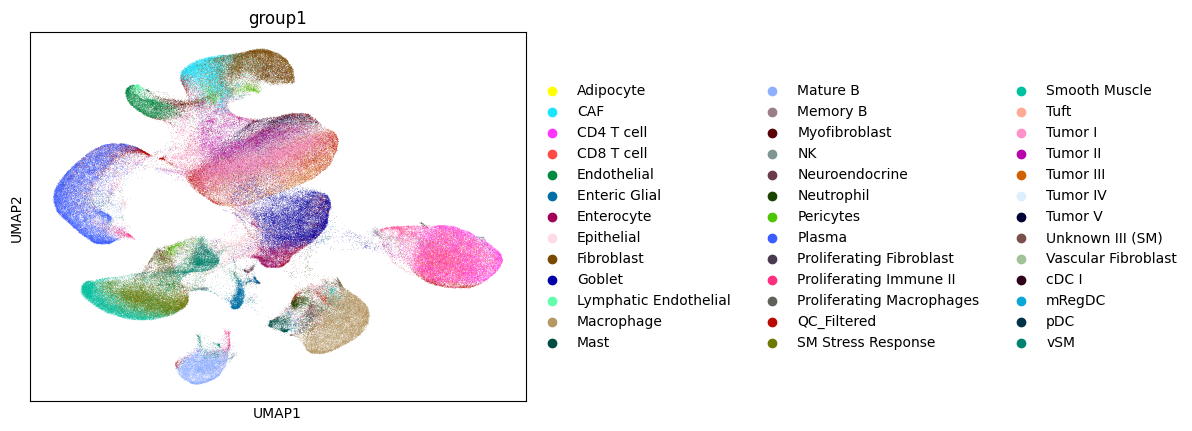

In [4]:
sc.pl.umap(adata,color='group1')

## Remove cell types with small numbers

In [ ]:
adata = adata[adata.obs["group1"] != "QC_Filtered"]
min_n = 5000 
ct_counts = adata.obs["group1"].value_counts()
keep_types = ct_counts[ct_counts >= min_n].index
adata_sub = adata[adata.obs["group1"].isin(keep_types)].copy()

adata_sub.var_names_make_unique()
if('counts') not in adata_sub.layers.keys():
    adata_sub.layers["counts"] = adata_sub.X.copy()

/Users/weihangzhang/opt/anaconda3/envs/ST-env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


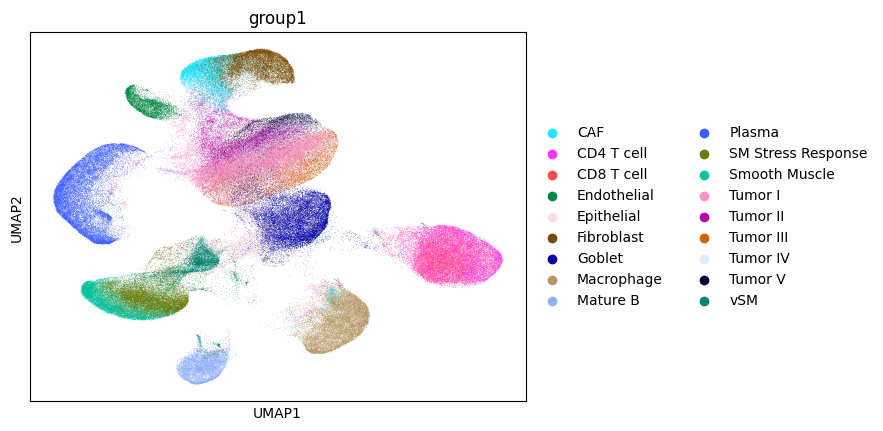

In [6]:
sc.pl.umap(adata_sub,color='group1')

## Convert gene counts into normalized gene expression per-cell type for gene selection

In [10]:
genemeanpd, genemeanpdfc = gene_lambda_by_ct(adata_sub, ctcol = 'group1')

[Log] 18552 cells for cell type Goblet
dimension of cell by gene count (18552, 18082)
[Log] 8688 cells for cell type Mature B
dimension of cell by gene count (8688, 18082)
[Log] 8208 cells for cell type Tumor V
dimension of cell by gene count (8208, 18082)
[Log] 27032 cells for cell type Tumor I
dimension of cell by gene count (27032, 18082)
[Log] 13303 cells for cell type Smooth Muscle
dimension of cell by gene count (13303, 18082)
[Log] 8787 cells for cell type vSM
dimension of cell by gene count (8787, 18082)
[Log] 5966 cells for cell type Tumor IV
dimension of cell by gene count (5966, 18082)
[Log] 22116 cells for cell type Plasma
dimension of cell by gene count (22116, 18082)
[Log] 14116 cells for cell type SM Stress Response
dimension of cell by gene count (14116, 18082)
[Log] 11481 cells for cell type CD8 T cell
dimension of cell by gene count (11481, 18082)
[Log] 5460 cells for cell type Endothelial
dimension of cell by gene count (5460, 18082)
[Log] 9620 cells for cell type Tu

## Select cell type-informative genes.

- Min gene lambda 0.000125 , logFC 0.5. 
- This is example cutoff refers to RCTD STYLE: "Using the estimated cell type expression profiles 𝜇ˆ𝑘,𝑗, we select differentially expressed genes that will be informative when estimating cell type proportions. For each cell type in the scRNA-seq reference, we select genes with minimum average expression above .0625 counts per 500 and at least 0.5 log-fold-change compared to the average expression across all cell types. "

In [11]:
genemeanpd_filtered = select_ct_informative_genes_basic(genemeanpd, genemeanpdfc, exprcut = 0.000125, fccut = 2**0.5)

18071 genes after removing MT- and Ribo
6008 genes after further removing RCTD threshold gene expression 0.0125
6008 genes after further removing RCTD logfc log2 0.5
(6008, 18)


## Re-calculate the gene labmdas for the selected celltype-informative genes


In [12]:
adata_markergs = adata_sub[:, genemeanpd_filtered.index]
genemeanpd_markergs, genemeanpdfc_markergs = gene_lambda_by_ct(adata_markergs, ctcol = 'group1')

[Log] 18552 cells for cell type Goblet
dimension of cell by gene count (18552, 6008)
[Log] 8688 cells for cell type Mature B
dimension of cell by gene count (8688, 6008)
[Log] 8208 cells for cell type Tumor V
dimension of cell by gene count (8208, 6008)
[Log] 27032 cells for cell type Tumor I
dimension of cell by gene count (27032, 6008)
[Log] 13303 cells for cell type Smooth Muscle
dimension of cell by gene count (13303, 6008)
[Log] 8787 cells for cell type vSM
dimension of cell by gene count (8787, 6008)
[Log] 5966 cells for cell type Tumor IV
dimension of cell by gene count (5966, 6008)
[Log] 22116 cells for cell type Plasma
dimension of cell by gene count (22116, 6008)
[Log] 14116 cells for cell type SM Stress Response
dimension of cell by gene count (14116, 6008)
[Log] 11481 cells for cell type CD8 T cell
dimension of cell by gene count (11481, 6008)
[Log] 5460 cells for cell type Endothelial
dimension of cell by gene count (5460, 6008)
[Log] 9620 cells for cell type Tumor II
dime

## Save the gene-by-cell-type lambdas matrix

In [ ]:
outfile = "DATA/lambda_matrix.csv"
genemeanpd_markergs.to_csv(outfile,sep=',')
